# Milestone 5: Prediction Failure Analysis

**Contributor:** Manasa  
**Issue:** #22 — Analyse prediction failures

Compare the saved M2 and M4 predictions on the same 5,512 test images.
This notebook examines corrected, new, and shared errors, records a reproducible
18-image visual review, and describes prediction scores on incorrect outputs.
No model inference or retraining is performed; a GPU is not required.

Visual notes are descriptive observations at the displayed scale, not expert
annotations or confirmed causes. The M2/M4 training-schedule difference and
patient overlap remain limitations. Code, saved outputs, and original execution
counts are retained; one identical repeated chart cell and the final empty cell
were removed. This notebook requires the original Drive inputs to rerun.

## 1. Environment and Shared Paths


In [1]:
import platform

import numpy as np
import pandas as pd

SEED = 42

print("Python version:", platform.python_version())
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Analysis seed:", SEED)
print("Analysis inputs: saved M2 and M4 predictions.")

Python version: 3.13.16
NumPy version: 2.1.3
Pandas version: 2.2.3
Analysis seed: 42
Analysis inputs: saved M2 and M4 predictions.


In [2]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/malaria_danet")
BASELINE_DIR = PROJECT_DIR / "baseline_evaluation"
M4_EVALUATION_DIR = PROJECT_DIR / "milestone4" / "model_evaluation"
M5_DIR = PROJECT_DIR / "milestone5" / "failure_analysis"
FIGURES_DIR = M5_DIR / "figures"

BASELINE_PREDICTIONS_PATH = BASELINE_DIR / "test_predictions.csv"
M4_PREDICTIONS_PATH = M4_EVALUATION_DIR / "test_predictions.csv"
MANIFEST_PATH = (
    PROJECT_DIR / "milestone4" / "data_preparation" / "split_manifest.csv"
)

M5_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Baseline predictions found:", BASELINE_PREDICTIONS_PATH.is_file())
print("M4 predictions found:", M4_PREDICTIONS_PATH.is_file())
print("Split manifest found:", MANIFEST_PATH.is_file())
print("M5 outputs:", M5_DIR)

Baseline predictions found: True
M4 predictions found: True
Split manifest found: True
M5 outputs: /content/drive/MyDrive/malaria_danet/milestone5/failure_analysis


## 2. Input Predictions and Test Alignment


In [4]:
baseline_predictions = pd.read_csv(BASELINE_PREDICTIONS_PATH)
modified_predictions = pd.read_csv(M4_PREDICTIONS_PATH)
manifest = pd.read_csv(MANIFEST_PATH)

print("Baseline prediction rows:", len(baseline_predictions))
print("M4 prediction rows:", len(modified_predictions))
print("Manifest rows:", len(manifest))

print("\nBaseline columns:")
print(baseline_predictions.columns.tolist())

print("\nM4 columns:")
print(modified_predictions.columns.tolist())

Baseline prediction rows: 5512
M4 prediction rows: 5512
Manifest rows: 27558

Baseline columns:
['relative_path', 'true_label', 'predicted_label', 'uninfected_probability', 'parasitized_probability', 'confidence', 'correct', 'true_class', 'predicted_class']

M4 columns:
['relative_path', 'filename', 'class_name', 'label', 'width', 'height', 'sha256', 'official_patient_id', 'split', 'predicted_label', 'parasitized_probability', 'log_probability_uninfected', 'log_probability_parasitized', 'correct', 'predicted_class']


In [5]:
test_records = manifest[
    manifest["split"] == "test"
].reset_index(drop=True)

assert len(test_records) == 5512
assert test_records["relative_path"].is_unique

for predictions in [baseline_predictions, modified_predictions]:
    assert predictions["relative_path"].is_unique
    assert set(predictions["relative_path"]) == set(
        test_records["relative_path"]
    )

baseline_aligned = (
    baseline_predictions.set_index("relative_path")
    .loc[test_records["relative_path"]]
    .reset_index()
)

modified_aligned = (
    modified_predictions.set_index("relative_path")
    .loc[test_records["relative_path"]]
    .reset_index()
)

assert np.array_equal(
    baseline_aligned["true_label"].to_numpy(),
    test_records["label"].to_numpy(),
)
assert np.array_equal(
    modified_aligned["label"].to_numpy(),
    test_records["label"].to_numpy(),
)

print("Both prediction files align to the same 5,512 test images.")
print("True labels match the shared manifest.")

Both prediction files align to the same 5,512 test images.
True labels match the shared manifest.


## 3. Paired Outcomes and Error Counts


In [6]:
analysis_df = test_records.copy()

analysis_df["baseline_prediction"] = baseline_aligned[
    "predicted_label"
].to_numpy()
analysis_df["modified_prediction"] = modified_aligned[
    "predicted_label"
].to_numpy()

analysis_df["baseline_parasitized_probability"] = baseline_aligned[
    "parasitized_probability"
].to_numpy()
analysis_df["modified_parasitized_probability"] = modified_aligned[
    "parasitized_probability"
].to_numpy()

baseline_correct = analysis_df["baseline_prediction"].eq(
    analysis_df["label"]
)
modified_correct = analysis_df["modified_prediction"].eq(
    analysis_df["label"]
)

analysis_df["paired_outcome"] = np.select(
    [
        baseline_correct & modified_correct,
        ~baseline_correct & modified_correct,
        baseline_correct & ~modified_correct,
    ],
    [
        "Both correct",
        "Corrected baseline error",
        "New modified-model error",
    ],
    default="Both wrong",
)

analysis_df.to_csv(M5_DIR / "paired_predictions.csv", index=False)

print("Paired prediction outcomes:")
display(analysis_df["paired_outcome"].value_counts())
print("Paired analysis table saved.")

Paired prediction outcomes:


,count
paired_outcome,
Both correct,5258
Both wrong,123
Corrected baseline error,79
New modified-model error,52


Paired analysis table saved.


In [7]:
for model_name in ["baseline", "modified"]:
    predicted = analysis_df[f"{model_name}_prediction"]
    actual = analysis_df["label"]

    analysis_df[f"{model_name}_outcome"] = np.select(
        [
            (actual == 0) & (predicted == 0),
            (actual == 1) & (predicted == 1),
            (actual == 0) & (predicted == 1),
        ],
        ["True negative", "True positive", "False positive"],
        default="False negative",
    )

outcome_order = [
    "True negative",
    "True positive",
    "False positive",
    "False negative",
]

outcome_counts_df = pd.DataFrame({
    "baseline": analysis_df["baseline_outcome"].value_counts(),
    "modified": analysis_df["modified_outcome"].value_counts(),
}).reindex(outcome_order)

outcome_counts_df["change"] = (
    outcome_counts_df["modified"] - outcome_counts_df["baseline"]
)
outcome_counts_df.index.name = "outcome"

outcome_counts_df.to_csv(M5_DIR / "outcome_counts.csv")
analysis_df.to_csv(M5_DIR / "paired_predictions.csv", index=False)

display(outcome_counts_df)
print("Outcome counts and updated analysis table saved.")

,baseline,modified,change
outcome,,,
True negative,2671,2667,-4
True positive,2639,2670,31
False positive,85,89,4
False negative,117,86,-31


Outcome counts and updated analysis table saved.


In [8]:
error_group_order = [
    "Corrected baseline error",
    "New modified-model error",
    "Both wrong",
]

paired_error_counts_df = pd.crosstab(
    analysis_df["paired_outcome"],
    analysis_df["class_name"],
).reindex(
    index=error_group_order,
    columns=["Uninfected", "Parasitized"],
    fill_value=0,
)

paired_error_counts_df["total"] = paired_error_counts_df.sum(axis=1)

assert paired_error_counts_df["total"].tolist() == [79, 52, 123]

paired_error_counts_df.to_csv(
    M5_DIR / "paired_errors_by_class.csv"
)

print("Uninfected errors correspond to false positives.")
print("Parasitized errors correspond to false negatives.")
display(paired_error_counts_df)
print("Paired error breakdown saved.")

Uninfected errors correspond to false positives.
Parasitized errors correspond to false negatives.


class_name,Uninfected,Parasitized,total
paired_outcome,,,
Corrected baseline error,27,52,79
New modified-model error,31,21,52
Both wrong,58,65,123


Paired error breakdown saved.


## 4. Corrected, New, and Shared Errors by Class


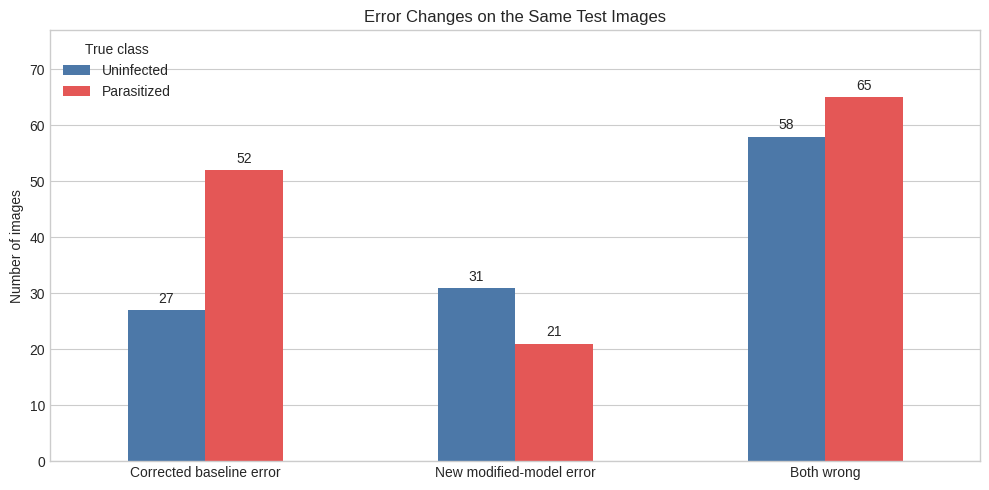

In [9]:
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")

ax = paired_error_counts_df[
    ["Uninfected", "Parasitized"]
].plot(
    kind="bar",
    figsize=(10, 5),
    color=["#4C78A8", "#E45756"],
    rot=0,
)

for container in ax.containers:
    ax.bar_label(container, padding=3, fmt="%d")

ax.set_title("Error Changes on the Same Test Images")
ax.set_xlabel("")
ax.set_ylabel("Number of images")
ax.legend(title="True class")
ax.set_ylim(0, paired_error_counts_df[
    ["Uninfected", "Parasitized"]
].to_numpy().max() + 12)
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "paired_errors_by_class.png", dpi=200)
plt.show()

## 5. Image Acquisition and Integrity Verification


In [10]:
DATA_ROOT = Path("/content/malaria_data")
IMAGE_ROOT = DATA_ROOT / "cell_images"
ZIP_PATH = DATA_ROOT / "cell_images.zip"

DATASET_URL = "https://data.lhncbc.nlm.nih.gov/public/Malaria/cell_images.zip"

DATA_ROOT.mkdir(parents=True, exist_ok=True)

print("Image folder:", IMAGE_ROOT)
print("Dataset already extracted:", IMAGE_ROOT.is_dir())
print("Dataset archive found:", ZIP_PATH.is_file())

Image folder: /content/malaria_data/cell_images
Dataset already extracted: False
Dataset archive found: False


In [11]:
import subprocess

subprocess.run(
    ["wget", "-c", "--show-progress", "-O", str(ZIP_PATH), DATASET_URL],
    check=True,
)

print(f"Downloaded file size: {ZIP_PATH.stat().st_size / 1024**2:.1f} MB")

Downloaded file size: 337.1 MB


In [12]:
import zipfile

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    archive.extractall(DATA_ROOT)

test_image_paths = test_records["relative_path"].map(
    lambda path: IMAGE_ROOT / path
)
missing_paths = test_image_paths[~test_image_paths.map(Path.exists)]

print("Test images checked:", len(test_image_paths))
print("Missing images:", len(missing_paths))

assert missing_paths.empty, "Some test images are missing."

print("Images are ready for visual failure analysis.")

Test images checked: 5512
Missing images: 0
Images are ready for visual failure analysis.


In [13]:
import hashlib

def file_hash(file_path):
    hasher = hashlib.sha256()

    with open(file_path, "rb") as file:
        for chunk in iter(lambda: file.read(8192), b""):
            hasher.update(chunk)

    return hasher.hexdigest()

image_hashes = test_image_paths.map(file_hash)
hash_matches = image_hashes.eq(test_records["sha256"])

assert hash_matches.all(), "Some test images differ from the saved manifest."

print("Test images checked:", len(hash_matches))
print("Hash mismatches:", int((~hash_matches).sum()))
print("All image contents match the saved manifest.")

Test images checked: 5512
Hash mismatches: 0
All image contents match the saved manifest.


## 6. Reproducible Visual Review Sample

Three images per true class and paired-error group are selected using seed 42.


In [14]:
review_groups = [
    "Corrected baseline error",
    "New modified-model error",
    "Both wrong",
]

review_samples = []

for group_index, group_name in enumerate(review_groups, start=1):
    for class_name in ["Uninfected", "Parasitized"]:
        candidates = analysis_df[
            (analysis_df["paired_outcome"] == group_name)
            & (analysis_df["class_name"] == class_name)
        ]

        sample = candidates.sample(n=3, random_state=SEED).copy()
        class_code = "U" if class_name == "Uninfected" else "P"

        sample["review_id"] = [
            f"G{group_index}-{class_code}{number}"
            for number in range(1, len(sample) + 1)
        ]

        review_samples.append(sample)

review_examples_df = pd.concat(review_samples, ignore_index=True)

review_examples_df.to_csv(
    M5_DIR / "visual_review_examples.csv",
    index=False,
)

print("Selected review images:", len(review_examples_df))
display(review_examples_df[[
    "review_id",
    "paired_outcome",
    "class_name",
    "baseline_prediction",
    "modified_prediction",
]])

Selected review images: 18


,review_id,paired_outcome,class_name,baseline_prediction,modified_prediction
0,G1-U1,Corrected baseline error,Uninfected,1,0
1,G1-U2,Corrected baseline error,Uninfected,1,0
2,G1-U3,Corrected baseline error,Uninfected,1,0
3,G1-P1,Corrected baseline error,Parasitized,0,1
4,G1-P2,Corrected baseline error,Parasitized,0,1
5,G1-P3,Corrected baseline error,Parasitized,0,1
6,G2-U1,New modified-model error,Uninfected,0,1
7,G2-U2,New modified-model error,Uninfected,0,1
8,G2-U3,New modified-model error,Uninfected,0,1
9,G2-P1,New modified-model error,Parasitized,1,0


## 7. Shared Error Examples


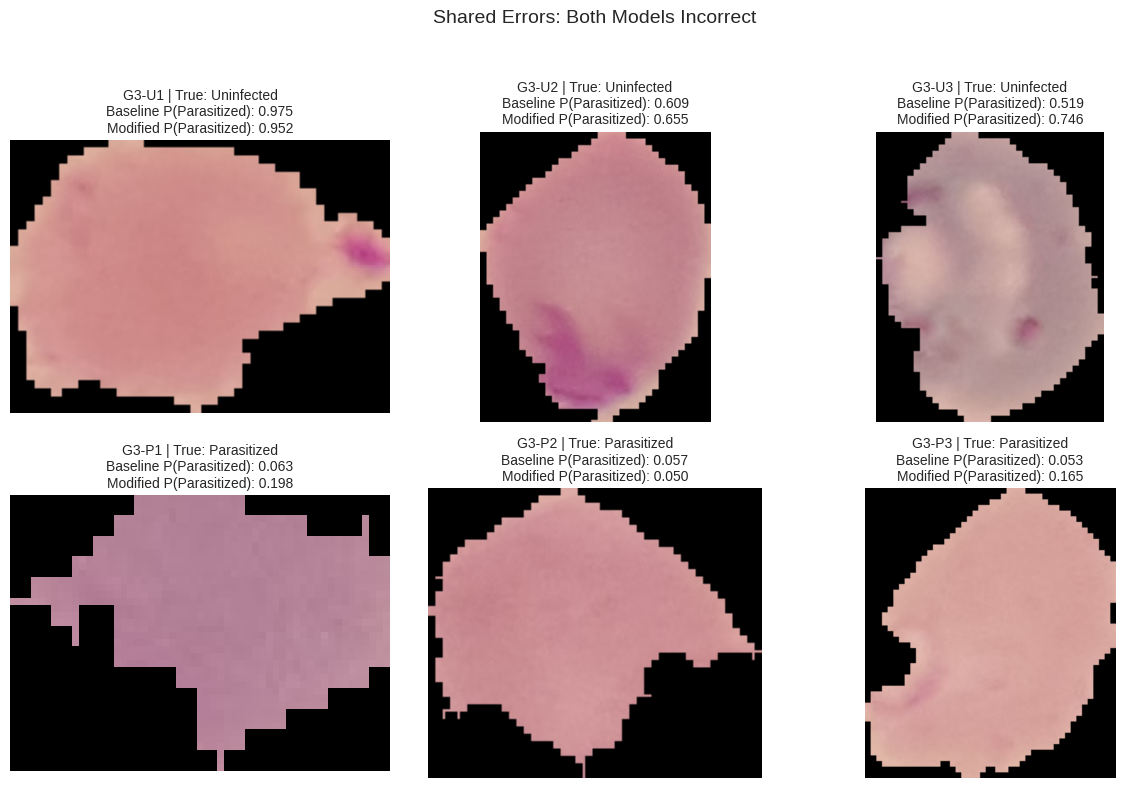

In [15]:
from PIL import Image

shared_examples = review_examples_df[
    review_examples_df["paired_outcome"] == "Both wrong"
]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, (_, row) in zip(axes.flat, shared_examples.iterrows()):
    with Image.open(IMAGE_ROOT / row["relative_path"]) as image:
        ax.imshow(image.convert("RGB"))

    ax.set_title(
        f"{row['review_id']} | True: {row['class_name']}\n"
        f"Baseline P(Parasitized): "
        f"{row['baseline_parasitized_probability']:.3f}\n"
        f"Modified P(Parasitized): "
        f"{row['modified_parasitized_probability']:.3f}",
        fontsize=10,
    )
    ax.axis("off")

fig.suptitle("Shared Errors: Both Models Incorrect", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig(FIGURES_DIR / "shared_error_examples.png", dpi=200)
plt.show()

## 8. Corrected Baseline Error Examples


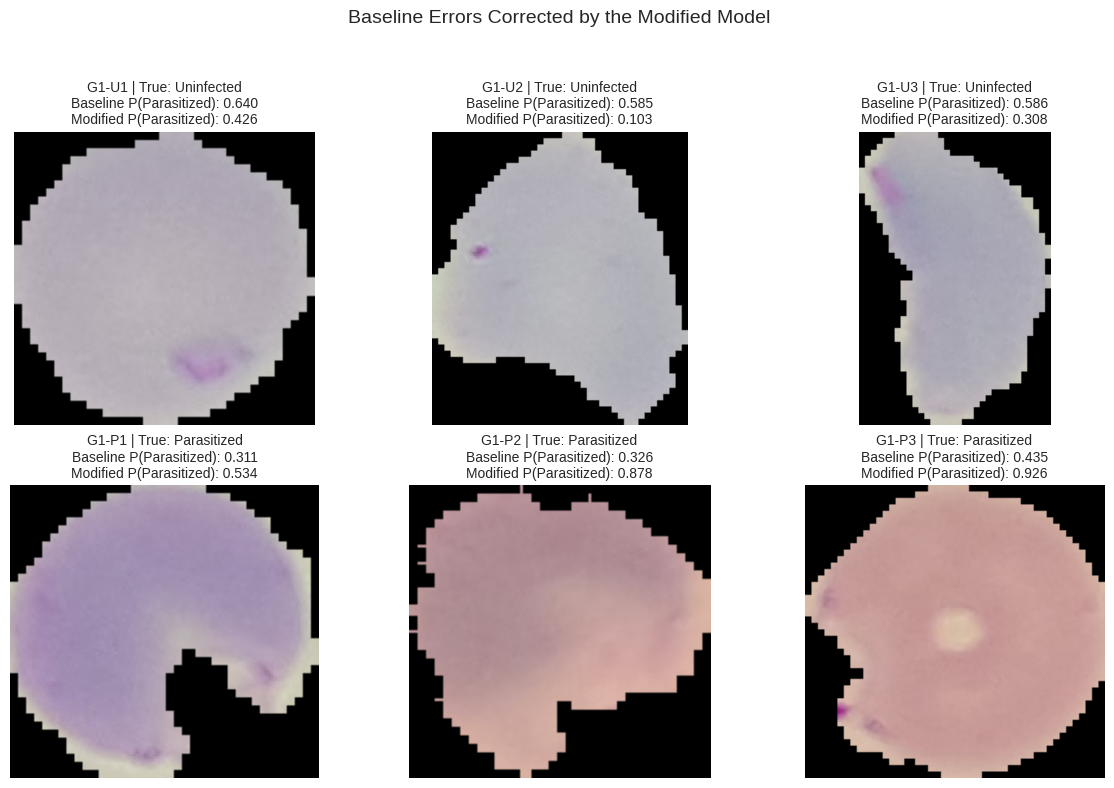

In [16]:
corrected_examples = review_examples_df[
    review_examples_df["paired_outcome"] == "Corrected baseline error"
]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, (_, row) in zip(axes.flat, corrected_examples.iterrows()):
    with Image.open(IMAGE_ROOT / row["relative_path"]) as image:
        ax.imshow(image.convert("RGB"))

    ax.set_title(
        f"{row['review_id']} | True: {row['class_name']}\n"
        f"Baseline P(Parasitized): "
        f"{row['baseline_parasitized_probability']:.3f}\n"
        f"Modified P(Parasitized): "
        f"{row['modified_parasitized_probability']:.3f}",
        fontsize=10,
    )
    ax.axis("off")

fig.suptitle("Baseline Errors Corrected by the Modified Model", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig(FIGURES_DIR / "corrected_error_examples.png", dpi=200)
plt.show()

## 9. New Modified-Model Error Examples


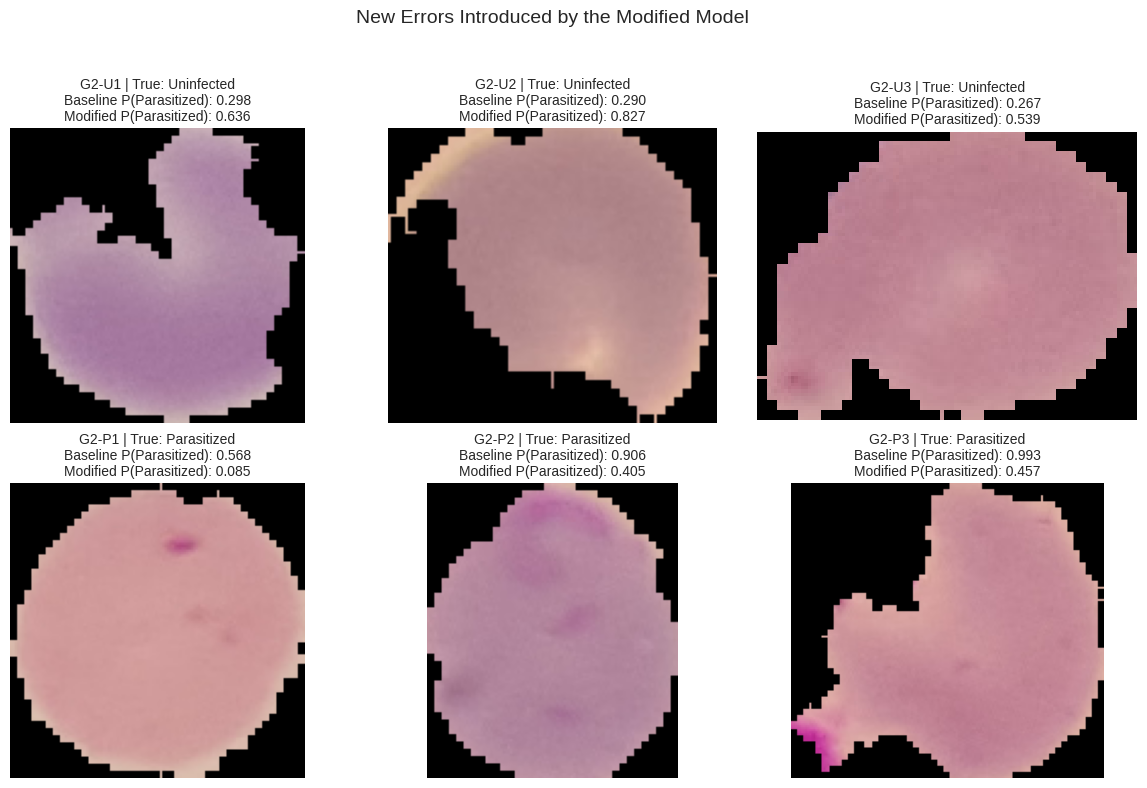

In [18]:
new_error_examples = review_examples_df[
    review_examples_df["paired_outcome"] == "New modified-model error"
]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, (_, row) in zip(axes.flat, new_error_examples.iterrows()):
    with Image.open(IMAGE_ROOT / row["relative_path"]) as image:
        ax.imshow(image.convert("RGB"))

    ax.set_title(
        f"{row['review_id']} | True: {row['class_name']}\n"
        f"Baseline P(Parasitized): "
        f"{row['baseline_parasitized_probability']:.3f}\n"
        f"Modified P(Parasitized): "
        f"{row['modified_parasitized_probability']:.3f}",
        fontsize=10,
    )
    ax.axis("off")

fig.suptitle("New Errors Introduced by the Modified Model", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig(FIGURES_DIR / "new_error_examples.png", dpi=200)
plt.show()

## 10. Per-Image Visual Observations

Descriptions are observations from the displayed examples; they do not establish parasite identity, label errors, or error causes.


In [19]:
visual_notes = {
    "G1-U1": "Pale cell with a purple region near the lower edge.",
    "G1-U2": "Pale cell with a small localized purple spot.",
    "G1-U3": "Elongated outline with purple coloration near an edge.",
    "G1-P1": "Diffuse purple coloration and an irregular lower outline.",
    "G1-P2": "Uneven pink coloration with a notched outline.",
    "G1-P3": "Pale central region and purple spots near the lower edge.",
    "G2-U1": "Diffuse purple coloration with a deeply notched outline.",
    "G2-U2": "Uneven pink coloration and an irregular outline.",
    "G2-U3": "Pink cell with a small purple region near the lower edge.",
    "G2-P1": "Pink cell with a localized purple spot near the upper region.",
    "G2-P2": "Diffuse purple coloration with a darker upper edge.",
    "G2-P3": "Deeply notched outline with purple coloration at an edge.",
    "G3-U1": "Pink cell with a prominent purple region near the right edge.",
    "G3-U2": "Pink cell with a broad purple region near the lower edge.",
    "G3-U3": "Uneven coloration with several localized purple regions.",
    "G3-P1": "Irregular outline; distinct internal features are less apparent.",
    "G3-P2": "Uneven pink coloration; distinct internal features are less apparent.",
    "G3-P3": "Pale central region with faint internal colour variation.",
}

review_examples_df["visual_observation"] = (
    review_examples_df["review_id"].map(visual_notes)
)
review_examples_df["interpretation"] = (
    "Descriptive observation at displayed scale; error cause not established."
)

assert review_examples_df["visual_observation"].notna().all()

review_examples_df.to_csv(
    M5_DIR / "visual_review_examples.csv",
    index=False,
)

display(review_examples_df[["review_id", "visual_observation"]])
print("Visual observations saved for all 18 reviewed images.")

,review_id,visual_observation
0,G1-U1,Pale cell with a purple region near the lower ...
1,G1-U2,Pale cell with a small localized purple spot.
2,G1-U3,Elongated outline with purple coloration near ...
3,G1-P1,Diffuse purple coloration and an irregular low...
4,G1-P2,Uneven pink coloration with a notched outline.
5,G1-P3,Pale central region and purple spots near the ...
6,G2-U1,Diffuse purple coloration with a deeply notche...
7,G2-U2,Uneven pink coloration and an irregular outline.
8,G2-U3,Pink cell with a small purple region near the ...
9,G2-P1,Pink cell with a localized purple spot near th...


Visual observations saved for all 18 reviewed images.


## 11. Prediction Scores on Errors

The 0.90 threshold is descriptive. Predicted-class probabilities are not established as calibrated certainty.


In [20]:
confidence_rows = []

for model_name in ["baseline", "modified"]:
    probability = analysis_df[
        f"{model_name}_parasitized_probability"
    ]

    assert probability.between(0, 1).all()

    analysis_df[f"{model_name}_predicted_probability"] = np.where(
        analysis_df[f"{model_name}_prediction"] == 1,
        probability,
        1 - probability,
    )

    for error_type in ["False positive", "False negative"]:
        errors = analysis_df[
            analysis_df[f"{model_name}_outcome"] == error_type
        ]
        scores = errors[f"{model_name}_predicted_probability"]

        confidence_rows.append({
            "model": model_name,
            "error_type": error_type,
            "total_errors": len(errors),
            "median_predicted_probability": float(scores.median()),
            "errors_with_score_at_least_0.90": int((scores >= 0.90).sum()),
        })

error_confidence_df = pd.DataFrame(confidence_rows)

error_confidence_df.to_csv(
    M5_DIR / "error_confidence_summary.csv",
    index=False,
)
analysis_df.to_csv(M5_DIR / "paired_predictions.csv", index=False)

display(error_confidence_df.round(4))
print("Error confidence summary saved.")

,model,error_type,total_errors,median_predicted_probability,errors_with_score_at_least_0.90
0,baseline,False positive,85,0.8303,34
1,baseline,False negative,117,0.8350,46
2,modified,False positive,89,0.7717,23
3,modified,False negative,86,0.8334,36


Error confidence summary saved.


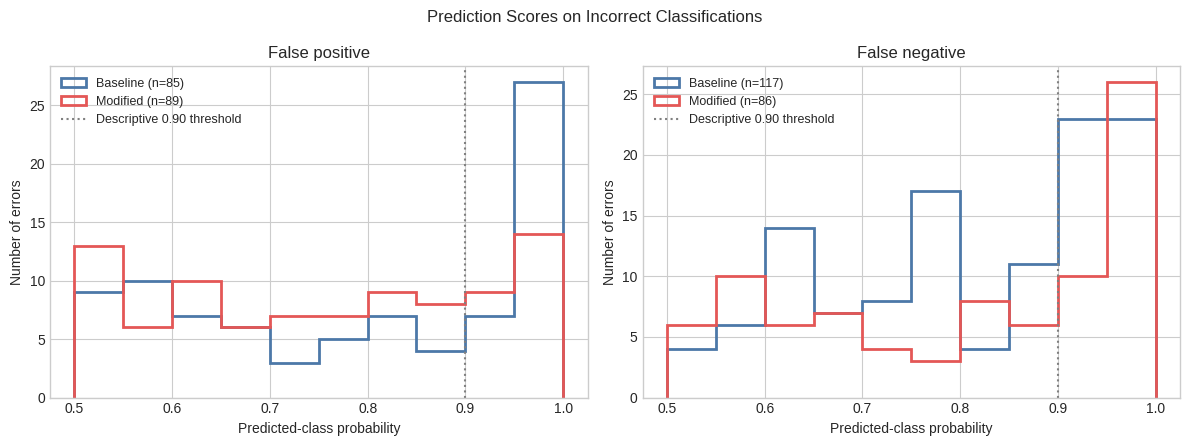

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
bins = np.linspace(0.5, 1.0, 11)

for ax, error_type in zip(
    axes,
    ["False positive", "False negative"],
):
    for model_name, color in [
        ("baseline", "#4C78A8"),
        ("modified", "#E45756"),
    ]:
        errors = analysis_df[
            analysis_df[f"{model_name}_outcome"] == error_type
        ]

        ax.hist(
            errors[f"{model_name}_predicted_probability"],
            bins=bins,
            histtype="step",
            linewidth=2,
            color=color,
            label=f"{model_name.capitalize()} (n={len(errors)})",
        )

    ax.axvline(
        0.90,
        color="gray",
        linestyle=":",
        label="Descriptive 0.90 threshold",
    )
    ax.set_title(error_type)
    ax.set_xlabel("Predicted-class probability")
    ax.set_ylabel("Number of errors")
    ax.legend(fontsize=9)

fig.suptitle("Prediction Scores on Incorrect Classifications")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "error_probability_distributions.png", dpi=200)
plt.show()

## 12. Descriptive Visual Pattern Groups

Groups overlap and describe only the selected examples; their frequency does not estimate prevalence across all errors.


In [22]:
visual_patterns = [
    {
        "pattern": "Localized purple spots or edge regions",
        "review_ids": (
            "G1-U1, G1-U2, G1-U3, G1-P3, G2-U3, "
            "G2-P1, G2-P3, G3-U1, G3-U2, G3-U3"
        ),
        "interpretation": (
            "Present in corrected, new, and shared errors; "
            "not sufficient to explain prediction differences."
        ),
    },
    {
        "pattern": "Diffuse or uneven colour variation",
        "review_ids": (
            "G1-P1, G1-P2, G2-U1, G2-U2, G2-P2, "
            "G3-U3, G3-P2, G3-P3"
        ),
        "interpretation": (
            "Observed across outcome groups; "
            "stain robustness was not directly tested."
        ),
    },
    {
        "pattern": "Irregular or notched outlines",
        "review_ids": "G1-P1, G1-P2, G2-U1, G2-U2, G2-P3, G3-P1",
        "interpretation": (
            "Visible shape variation; its influence on predictions "
            "requires a separate controlled analysis."
        ),
    },
    {
        "pattern": "Less apparent internal features at displayed scale",
        "review_ids": "G3-P1, G3-P2, G3-P3",
        "interpretation": (
            "Observed in sampled shared false negatives; "
            "does not establish absence of parasites or label errors."
        ),
    },
]

visual_patterns_df = pd.DataFrame(visual_patterns)

visual_patterns_df.to_csv(
    M5_DIR / "visual_pattern_groups.csv",
    index=False,
)

display(visual_patterns_df)
print("Descriptive visual pattern groups saved.")

,pattern,review_ids,interpretation
0,Localized purple spots or edge regions,"G1-U1, G1-U2, G1-U3, G1-P3, G2-U3, G2-P1, G2-P...","Present in corrected, new, and shared errors; ..."
1,Diffuse or uneven colour variation,"G1-P1, G1-P2, G2-U1, G2-U2, G2-P2, G3-U3, G3-P...",Observed across outcome groups; stain robustne...
2,Irregular or notched outlines,"G1-P1, G1-P2, G2-U1, G2-U2, G2-P3, G3-P1",Visible shape variation; its influence on pred...
3,Less apparent internal features at displayed s...,"G3-P1, G3-P2, G3-P3",Observed in sampled shared false negatives; do...


Descriptive visual pattern groups saved.


## 13. Analysis Configuration and Environment


In [23]:
import json

analysis_config = {
    "milestone": 5,
    "issue": 22,
    "analysis": "Paired prediction failure analysis",
    "seed": SEED,
    "test_images": len(analysis_df),
    "baseline_predictions_sha256": file_hash(BASELINE_PREDICTIONS_PATH),
    "modified_predictions_sha256": file_hash(M4_PREDICTIONS_PATH),
    "split_manifest_sha256": file_hash(MANIFEST_PATH),
    "test_image_hash_mismatches": int((~hash_matches).sum()),
    "visual_sampling": {
        "method": "Random sampling within paired-outcome and true-class groups",
        "images_per_group_per_class": 3,
        "total_reviewed_images": len(review_examples_df),
        "seed": SEED,
    },
    "high_score_threshold": 0.90,
    "high_score_interpretation": (
        "Descriptive predicted-class probability; not calibrated certainty."
    ),
    "visual_review_scope": (
        "Observations from 18 sampled images at displayed scale. "
        "Groups overlap and do not estimate prevalence or establish causes."
    ),
    "model_inference_performed": False,
    "model_retraining_performed": False,
}

with open(M5_DIR / "failure_analysis_config.json", "w") as file:
    json.dump(analysis_config, file, indent=2)

print(json.dumps(analysis_config, indent=2))

{
  "milestone": 5,
  "issue": 22,
  "analysis": "Paired prediction failure analysis",
  "seed": 42,
  "test_images": 5512,
  "baseline_predictions_sha256": "6549e7538c78bfb2537dad295eb01dfa9e965cea48e5479bc35280c20efba07c",
  "modified_predictions_sha256": "cede5aac605fc8b4c0efdd8cde1ad3c703ba55c23848202f7990d18dd81a6a97",
  "split_manifest_sha256": "aea08bdec4626ae188204039369aafe14b3a9ac9ce0782077458d9428f26091d",
  "test_image_hash_mismatches": 0,
  "visual_sampling": {
    "method": "Random sampling within paired-outcome and true-class groups",
    "images_per_group_per_class": 3,
    "total_reviewed_images": 18,
    "seed": 42
  },
  "high_score_threshold": 0.9,
  "high_score_interpretation": "Descriptive predicted-class probability; not calibrated certainty.",
  "visual_review_scope": "Observations from 18 sampled images at displayed scale. Groups overlap and do not estimate prevalence or establish causes.",
  "model_inference_performed": false,
  "model_retraining_performed": f

In [24]:
import PIL
import matplotlib

analysis_environment = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "pillow": PIL.__version__,
    "matplotlib": matplotlib.__version__,
    "gpu_required": False,
}

with open(M5_DIR / "analysis_environment.json", "w") as file:
    json.dump(analysis_environment, file, indent=2)

print(json.dumps(analysis_environment, indent=2))

{
  "python": "3.13.16",
  "numpy": "2.1.3",
  "pandas": "2.2.3",
  "pillow": "11.3.0",
  "matplotlib": "3.10.0",
  "gpu_required": false
}


## 14. Failure Analysis Write-Up


In [25]:
failure_analysis = """# Milestone 5: Prediction Failure Analysis

## Scope
This analysis compares saved M2 baseline and M4 modified-model predictions
on the same 5,512 test images. Paths and labels were aligned, and all test
image hashes matched the shared manifest. No inference or retraining was performed.

## Error changes
The baseline made 202 errors; the modified model made 175.
The modified model corrected 79 baseline errors but introduced 52 new errors.
Both models misclassified 123 images.

| Error group | Uninfected | Parasitized | Total |
|---|---:|---:|---:|
| Corrected baseline errors | 27 | 52 | 79 |
| New modified-model errors | 31 | 21 | 52 |
| Shared errors | 58 | 65 | 123 |

False negatives decreased from 117 to 86: 52 were corrected and 21 new
false negatives appeared. False positives increased from 85 to 89:
27 were corrected and 31 new false positives appeared.

The aggregate improvement therefore does not mean every prediction improved.

## Visual review
We randomly sampled three images per true class from each of the corrected,
new-error, and shared-error groups, using seed 42: 18 images in total.

Observed patterns included localized purple spots or edge regions, diffuse
or uneven coloration, irregular outlines, and less apparent internal features
in the sampled shared false negatives at the displayed scale.

Similar visual features occurred across different outcome groups. These
observations do not establish which features the models used, why an error
occurred, or whether a dataset label is incorrect. Pattern groups overlap and
do not estimate prevalence across the full error set.

Per-image observations and identifiers are saved in visual_review_examples.csv.
The descriptive groups are saved in visual_pattern_groups.csv.

## Prediction scores on errors
Using a descriptive predicted-class probability threshold of 0.90:
- Baseline: 34 false positives and 46 false negatives scored at least 0.90.
- Modified model: 23 false positives and 36 false negatives scored at least 0.90.

Both models can assign high scores to incorrect predictions. These counts
do not establish calibration or clinical certainty.

## Limitations
- M2 switched to full precision after epoch 24; M4 switched after epoch 22.
  The training-schedule difference limits attribution solely to ColorJitter.
- The image-level split retains patient overlap across partitions.
- Results cover one dataset, one split, and one seed.
- Only 18 stratified random examples were visually reviewed.
- Visual observations lack expert annotation and causal validation.
- No explicit stain-shift, lighting-shift, or external-dataset test was performed.
- Statistical significance and clinical validity have not been established.

## Implications and future work
The modified run reduced missed infected cells on this fixed split, while
introducing additional false positives and retaining shared failures.
Future work should compare models under matched training schedules and
multiple seeds, use patient-independent evaluation, test predefined colour
shifts, and obtain expert review of ambiguous examples.

These are proposed follow-up studies, not completed experiments.
"""

FAILURE_ANALYSIS_PATH = M5_DIR / "failure_analysis.md"
FAILURE_ANALYSIS_PATH.write_text(failure_analysis, encoding="utf-8")

print(failure_analysis)
print("Write-up saved:", FAILURE_ANALYSIS_PATH)

# Milestone 5: Prediction Failure Analysis

## Scope
This analysis compares saved M2 baseline and M4 modified-model predictions
on the same 5,512 test images. Paths and labels were aligned, and all test
image hashes matched the shared manifest. No inference or retraining was performed.

## Error changes
The baseline made 202 errors; the modified model made 175.
The modified model corrected 79 baseline errors but introduced 52 new errors.
Both models misclassified 123 images.

| Error group | Uninfected | Parasitized | Total |
|---|---:|---:|---:|
| Corrected baseline errors | 27 | 52 | 79 |
| New modified-model errors | 31 | 21 | 52 |
| Shared errors | 58 | 65 | 123 |

False negatives decreased from 117 to 86: 52 were corrected and 21 new
false negatives appeared. False positives increased from 85 to 89:
27 were corrected and 31 new false positives appeared.

The aggregate improvement therefore does not mean every prediction improved.

## Visual review
We randomly sampled three images 

## 15. Artifact Checksums and Paper Handoff

Drive exports are stored under `milestone5/failure_analysis/`. The repository places those exports under `failure_analysis/artifacts/`, keeping figures under `artifacts/figures/`. The write-up, counts, and figures support the final paper and defence; they do not complete those deliverables.


In [26]:
artifact_names = [
    "paired_predictions.csv",
    "outcome_counts.csv",
    "paired_errors_by_class.csv",
    "visual_review_examples.csv",
    "visual_pattern_groups.csv",
    "error_confidence_summary.csv",
    "failure_analysis_config.json",
    "analysis_environment.json",
    "failure_analysis.md",
    "figures/paired_errors_by_class.png",
    "figures/shared_error_examples.png",
    "figures/corrected_error_examples.png",
    "figures/new_error_examples.png",
    "figures/error_probability_distributions.png",
]

artifacts = []

for name in artifact_names:
    path = M5_DIR / name
    assert path.is_file(), f"Missing artifact: {path}"

    artifacts.append({
        "filename": name,
        "size_bytes": path.stat().st_size,
        "sha256": file_hash(path),
    })

ARTIFACT_MANIFEST_PATH = M5_DIR / "failure_analysis_artifact_manifest.json"

with open(ARTIFACT_MANIFEST_PATH, "w") as file:
    json.dump(artifacts, file, indent=2)

display(pd.DataFrame(artifacts))
print("All 14 failure-analysis artifacts recorded.")
print("Artifact manifest saved:", ARTIFACT_MANIFEST_PATH)

,filename,size_bytes,sha256
0,paired_predictions.csv,1728131,b2c8dfac22ac883476f3b5effbae94b8f4173e6353eac7...
1,outcome_counts.csv,136,45a3aed8077bd18c3e35948da476c0ec6a9c772a490e0a...
2,paired_errors_by_class.csv,133,c70f3e98d0e1db2cff6cf4fecabb6b6d05cff6f531ef61...
3,visual_review_examples.csv,7953,e2bf7d9a1db1ba8733fb5b7f22513ba8cb6c4352332237...
4,visual_pattern_groups.csv,750,60d74221c7607efe8ba02c398d1f35a9ab8d5aa5adbcf8...
5,error_confidence_summary.csv,271,44246fa2df8b2f2d2a5b9e828fa9c0c3567d2411570978...
6,failure_analysis_config.json,1006,bb1b889c4b53e7c280c241e242d5173743c41fd9596a66...
7,analysis_environment.json,139,3c7cc6b57f9fb746f73b79a1f4f2f4ccbe655594af7e7a...
8,failure_analysis.md,3161,fcd46aaac3607c0db9bb987ec0d53e5594c6cefaa7d9bc...
9,figures/paired_errors_by_class.png,68536,372408e0cfbcb3cd5d428e9c03cca4835ee2b114882454...


All 14 failure-analysis artifacts recorded.
Artifact manifest saved: /content/drive/MyDrive/malaria_danet/milestone5/failure_analysis/failure_analysis_artifact_manifest.json
